# Stage 3: The minimum variance frontier

For any target expected return, many portfolios of the 25 stocks can reach it. The **minimum
variance frontier** is the set of those portfolios with the lowest possible risk at each return.

Minimize  w′Σw  subject to  w′μ = target  and  w′1 = 1

Here w is the weights, μ the expected returns and Σ the covariance matrix. This stage has **no other
limits**, so short sales are allowed and there are no position caps. Stage 4 adds those.

We run this on both input sets from Stage 2, using **estimation months only**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmo import frontier as fr
from pmo import models
from pmo import returns as ret
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import FIGURES, MUTED, SERIES_1, SERIES_2, SURFACE, apply_style

apply_style()
config = load_config()
data = load()
stocks = data.universe["symbol"].tolist()
market = config.market_proxy

excess = ret.select_period(data.excess, data.periods, "estimation")
RISK_FREE = data.risk_free["rf"].loc[excess.index].mean() * 12


def textbook(frame):
    return models.textbook_inputs(frame[stocks])


def practical(frame):
    premium = data.factors_long.loc[:frame.index.max(), "MKT_RF"].mean()
    return models.practical_inputs(frame[stocks], frame[market], premium)


text_mean, text_cov = fr.annualize(*textbook(excess), RISK_FREE)
prac_mean, prac_cov = fr.annualize(*practical(excess), RISK_FREE)
text_frontier = fr.Frontier(text_mean, text_cov)
prac_frontier = fr.Frontier(prac_mean, prac_cov)
print(f"Risk-free rate {RISK_FREE:.2%}")

Risk-free rate 6.37%


## 1. The closed-form solution

With only these two constraints the problem has an exact answer. Define four numbers:

- A = 1′Σ⁻¹1
- B = 1′Σ⁻¹μ
- C = μ′Σ⁻¹μ
- D = AC − B²

The frontier is then a hyperbola:

σ²(μ) = (Aμ² − 2Bμ + C) / D

Its lowest point is the **global minimum variance (GMV) portfolio**, with weights Σ⁻¹1 / A, return
B/A and variance 1/A.

### Checking the math with a numerical optimizer

The two methods are independent, so their agreement is strong evidence that both are right. Stage 4
needs the optimizer, because constraints remove the closed-form answer.

In [2]:
rows = []
for name, frontier, (mean, cov) in [("Textbook", text_frontier, (text_mean, text_cov)),
                                    ("Practical", prac_frontier, (prac_mean, prac_cov))]:
    for target in [frontier.gmv_return, 0.20, 0.30]:
        exact = frontier.weights(target)
        solved = fr.solve_min_variance(mean, cov, target)
        rows.append({"inputs": name, "target": target,
                     "closed_form_vol": float(frontier.volatility(target)),
                     "optimizer_vol": fr.portfolio_stats(solved, mean, cov)[1],
                     "largest_weight_gap": (exact - solved).abs().max()})
pd.DataFrame(rows).style.format({"target": "{:.2%}", "closed_form_vol": "{:.4%}",
                                 "optimizer_vol": "{:.4%}", "largest_weight_gap": "{:.1e}"})

,inputs,target,closed_form_vol,optimizer_vol,largest_weight_gap
0,Textbook,14.23%,10.9154%,10.9154%,3.8e-14
1,Textbook,20.00%,11.8947%,11.8947%,2.7e-14
2,Textbook,30.00%,16.9149%,16.9149%,1.4e-14
3,Practical,12.84%,9.7112%,9.7112%,2.3e-14
4,Practical,20.00%,13.9374%,13.9374%,1.9e-14
5,Practical,30.00%,25.8594%,25.8594%,3.5e-14


## 2. The frontiers

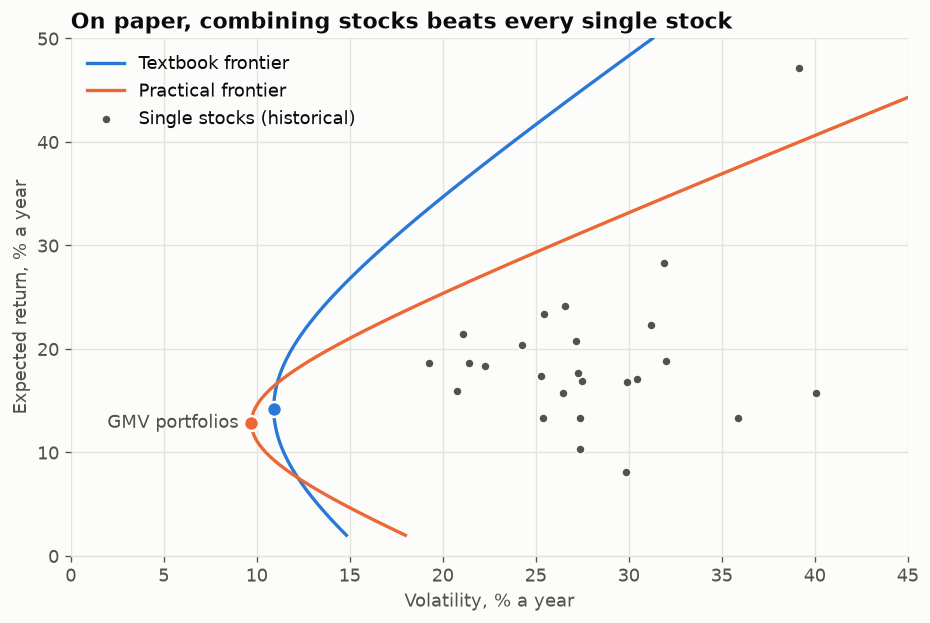

,Textbook,Practical
gmv_return,0.142,0.128
gmv_volatility,0.109,0.097
gmv_sharpe,0.720,0.666
stocks_shorted,9.000,6.000
short,0.350,0.294
gross,1.699,1.589
largest_long,0.206,0.182
largest_short,-0.107,-0.097


In [3]:
text_curve = text_frontier.curve(0.02, 0.50)
prac_curve = prac_frontier.curve(0.02, 0.50)
single_vol = np.sqrt(np.diag(text_cov))

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.grid(axis="x")
ax.plot(text_curve["volatility"] * 100, text_curve["expected_return"] * 100, color=SERIES_1,
        label="Textbook frontier")
ax.plot(prac_curve["volatility"] * 100, prac_curve["expected_return"] * 100, color=SERIES_2,
        label="Practical frontier")
ax.scatter(single_vol * 100, text_mean * 100, s=30, color=MUTED, edgecolor=SURFACE, zorder=3,
           label="Single stocks (historical)")
for frontier, color in [(text_frontier, SERIES_1), (prac_frontier, SERIES_2)]:
    ax.scatter(frontier.gmv_volatility * 100, frontier.gmv_return * 100, s=80, color=color,
               edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.text(prac_frontier.gmv_volatility * 100 - 0.7, prac_frontier.gmv_return * 100, "GMV portfolios",
        ha="right", va="center", color=MUTED)
ax.set_xlim(0, 45)
ax.set_ylim(0, 50)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Expected return, % a year")
ax.set_title("On paper, combining stocks beats every single stock")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "03_frontiers.png")
plt.show()

def summarize(frontier):
    weights = frontier.gmv_weights()
    return {"gmv_return": frontier.gmv_return, "gmv_volatility": frontier.gmv_volatility,
            "gmv_sharpe": (frontier.gmv_return - RISK_FREE) / frontier.gmv_volatility,
            "stocks_shorted": int((weights < 0).sum()), **fr.exposure(weights)}

pd.DataFrame({"Textbook": summarize(text_frontier), "Practical": summarize(prac_frontier)}).round(3)

The lowest-risk stock has about 19% volatility, yet the GMV portfolios promise about 10–11%,
which is the diversification effect at full strength. These promises are too good, though. The
market's Sharpe ratio was 0.34, and a Sharpe near 1 from large-cap stocks should raise suspicion.
Sections 5 and 6 test them.

## 3. The GMV portfolio

The GMV uses no expected returns, only covariances, so it is the frontier point least affected by
weak return estimates.

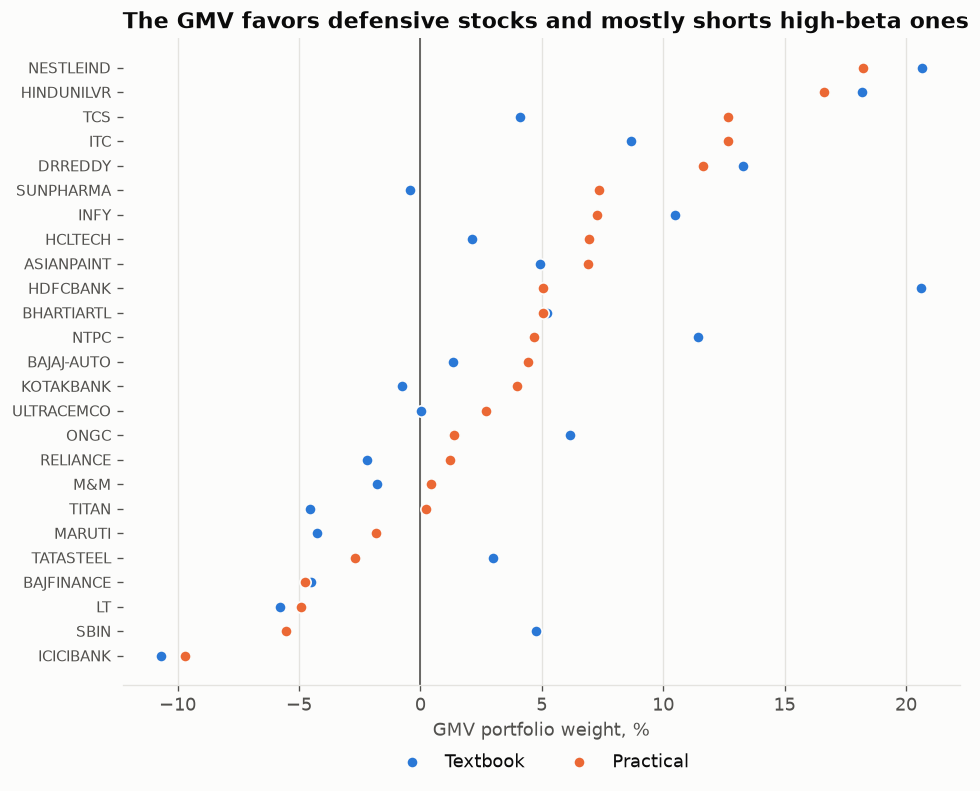

In [4]:
weights = pd.DataFrame({"Textbook": text_frontier.gmv_weights(),
                        "Practical": prac_frontier.gmv_weights()}).sort_values("Practical")
fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
positions = np.arange(len(weights))
ax.axvline(0, color=MUTED, linewidth=1)
ax.scatter(weights["Textbook"] * 100, positions, s=46, color=SERIES_1, edgecolor=SURFACE,
           zorder=3, label="Textbook")
ax.scatter(weights["Practical"] * 100, positions, s=46, color=SERIES_2, edgecolor=SURFACE,
           zorder=3, label="Practical")
ax.set_yticks(positions, weights.index, fontsize=9)
ax.set_xlabel("GMV portfolio weight, %")
ax.set_title("The GMV favors defensive stocks and mostly shorts high-beta ones")
ax.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.savefig(FIGURES / "03_gmv_weights.png")
plt.show()

## 4. The two-fund theorem

Every frontier portfolio is a mix of any two others. This matters in practice: an investor doesn't
need a new optimization for each target, just a split between two funds. It also leads directly to
Stage 5, where the risk-free asset becomes one of the two funds.

In [5]:
low, high = text_frontier.weights(0.15), text_frontier.weights(0.35)
mix = 0.75 * low + 0.25 * high
direct = text_frontier.weights(0.20)
print(f"Largest gap between 75/25 mix and direct 20% portfolio: {(mix - direct).abs().max():.1e}")

Largest gap between 75/25 mix and direct 20% portfolio: 5.6e-17


## 5. Can anyone actually hold these portfolios?

Without limits, higher targets need bigger short positions. Retail investors in India can't easily
hold short positions in the cash market, so these portfolios are mostly theoretical.

In [6]:
rows = []
for name, frontier in [("Textbook", text_frontier), ("Practical", prac_frontier)]:
    for target in [frontier.gmv_return, 0.20, 0.25, 0.30]:
        weights = frontier.weights(target)
        rows.append({"inputs": name, "target_return": target,
                     "volatility": float(frontier.volatility(target)),
                     "sharpe": (target - RISK_FREE) / float(frontier.volatility(target)),
                     **fr.exposure(weights)})
pd.DataFrame(rows).round(3)

,inputs,target_return,volatility,sharpe,short,gross,largest_long,largest_short
0,Textbook,0.142,0.109,0.720,0.350,1.699,0.206,-0.107
1,Textbook,0.200,0.119,1.146,0.263,1.525,0.198,-0.088
2,Textbook,0.250,0.140,1.327,0.295,1.590,0.212,-0.096
3,Textbook,0.300,0.169,1.397,0.523,2.045,0.323,-0.132
4,Practical,0.128,0.097,0.666,0.294,1.589,0.182,-0.097
5,Practical,0.200,0.139,0.978,0.506,2.012,0.204,-0.110
6,Practical,0.250,0.196,0.952,0.789,2.579,0.369,-0.193
7,Practical,0.300,0.259,0.914,1.162,3.324,0.540,-0.277


## 6. How stable are the weights?

If the data had come out slightly differently, how different would the portfolio be? To find out,
we resample the months with replacement, redo the estimate 500 times, and measure how much each
weight moves.

In [7]:
def stability(inputs, target):
    draws = fr.bootstrap_weights(excess, inputs, RISK_FREE, target=target, draws=500)
    sign = np.sign(draws.median())
    return {"average_weight_sd": draws.std().mean(),
            "average_90pct_range": (draws.quantile(0.95) - draws.quantile(0.05)).mean(),
            "chance_of_sign_flip": (np.sign(draws) != sign).mean().mean()}

pd.DataFrame({
    "Textbook, GMV": stability(textbook, None),
    "Practical, GMV": stability(practical, None),
    "Textbook, 20% target": stability(textbook, 0.20),
    "Practical, 20% target": stability(practical, 0.20),
}).T.round(3)

,average_weight_sd,average_90pct_range,chance_of_sign_flip
"Textbook, GMV",0.057,0.188,0.192
"Practical, GMV",0.021,0.068,0.066
"Textbook, 20% target",0.066,0.214,0.227
"Practical, 20% target",0.053,0.172,0.159


Practical inputs make the GMV about three times as stable. The gain is much smaller at the 20%
target because that portfolio depends on expected returns, which remain weak.

## 7. Do frontier portfolios deliver what they promise?

This is the key test. We build frontiers on the first two-thirds of the estimation period, then see
what those portfolios earned in the remaining months. The holdout is still untouched.

The test months include the March 2020 crash and a strong recovery, so compare the portfolios with
each other rather than focusing on their absolute returns.

Train to Jul 2019; test 51 months to Oct 2023


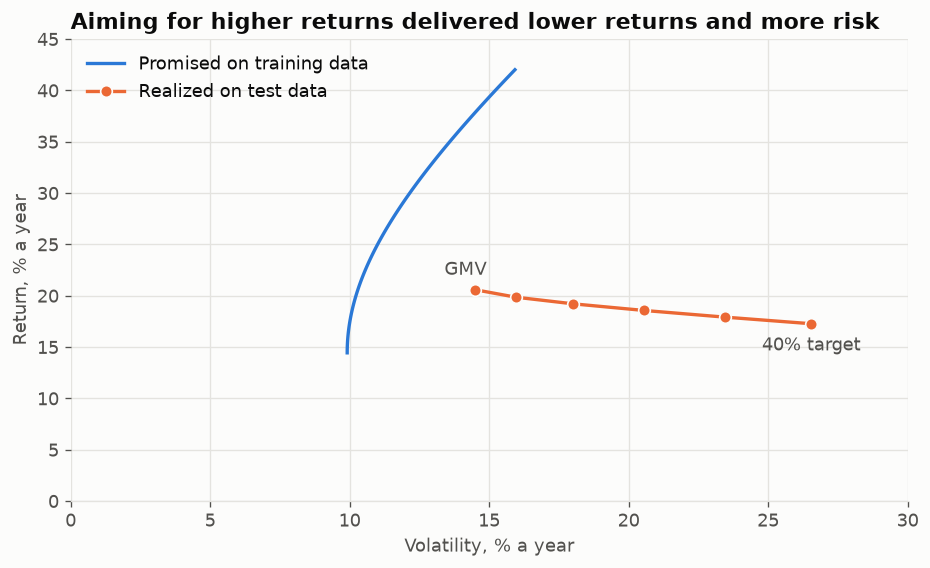

target_return  promised_volatility  realized_return  \
Textbook  0          0.144                0.099            0.206   
          1          0.200                0.102            0.198   
          2          0.250                0.110            0.192   
          3          0.300                0.122            0.186   
          4          0.350                0.136            0.179   
          5          0.400                0.152            0.173   
Practical 0          0.124                0.091            0.200   
          1          0.200                0.113            0.172   
          2          0.250                0.144            0.154   
          3          0.300                0.180            0.136   
          4          0.350                0.219            0.117   
          5          0.400                0.260            0.099   

             realized_volatility  
Textbook  0                0.145  
          1                0.160  
          2                0.180  
          3                0.206  
          4                0.234  
          5                0.265  
Practical 0                0.148  
          1                0.199  
          2                0.257  
          3                0.324  
          4                0.394  
          5                0.467

In [8]:
cut = 102
train, test = excess.iloc[:cut], excess.iloc[cut:]
print(f"Train to {train.index[-1]:%b %Y}; test {len(test)} months to {test.index[-1]:%b %Y}")

def delivery(inputs):
    frontier = fr.Frontier(*fr.annualize(*inputs(train), RISK_FREE))
    targets = [round(frontier.gmv_return, 4), 0.20, 0.25, 0.30, 0.35, 0.40]
    return frontier, fr.promised_vs_realized(train, test, inputs, RISK_FREE, targets)

text_train, text_result = delivery(textbook)
prac_train, prac_result = delivery(practical)
curve = text_train.curve(text_train.gmv_return, 0.42)

fig, ax = plt.subplots(figsize=(9, 5))
ax.grid(axis="x")
ax.plot(curve["volatility"] * 100, curve["expected_return"] * 100, color=SERIES_1,
        label="Promised on training data")
ax.plot(text_result["realized_volatility"] * 100, text_result["realized_return"] * 100,
        color=SERIES_2, marker="o", markersize=7, markeredgecolor=SURFACE, label="Realized on test data")
ax.annotate("GMV", (text_result["realized_volatility"].iloc[0] * 100,
                    text_result["realized_return"].iloc[0] * 100),
            xytext=(-6, 9), textcoords="offset points", ha="center", color=MUTED)
ax.annotate("40% target", (text_result["realized_volatility"].iloc[-1] * 100,
                           text_result["realized_return"].iloc[-1] * 100),
            xytext=(0, -16), textcoords="offset points", ha="center", color=MUTED)
ax.set_xlim(0, 30)
ax.set_ylim(0, 45)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Return, % a year")
ax.set_title("Aiming for higher returns delivered lower returns and more risk")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "03_promised_vs_realized.png")
plt.show()

equal = test[stocks].mean(axis=1)
benchmarks = pd.DataFrame({
    "realized_return": [equal.mean() * 12 + RISK_FREE, test[market].mean() * 12 + RISK_FREE],
    "realized_volatility": [equal.std() * np.sqrt(12), test[market].std() * np.sqrt(12)],
}, index=["Equal weight", "Market proxy"])
pd.concat({"Textbook": text_result, "Practical": prac_result}).round(3)

In [9]:
vol_ratio = test[market].std() / train[market].std()
print(f"Market volatility was {vol_ratio:.2f} times higher in the test months than in training.")
benchmarks.round(3)

Market volatility was 1.28 times higher in the test months than in training.


,realized_return,realized_volatility
Equal weight,0.242,0.182
Market proxy,0.175,0.192


Reading these results:

- **The return ordering reversed.** Higher targets earned lower returns, so the part of the frontier
  above the GMV showed no real reward for taking more risk.
- **Risk was understated everywhere.** Part of that is a calmer training period, since market
  volatility itself rose. But realized volatility grew much faster than promised as targets rose.
- **The GMV held up best.** It had the lowest risk and the highest return of the frontier
  portfolios, because it doesn't rely on expected returns.
- **The GMV did not clearly beat equal weight.** Their Sharpe ratios were about the same, near 1.0.
  The equal-weight portfolio earned more with more risk, needed no estimates and no shorting, though
  survivorship helps it here.
- **Practical inputs are not a cure.** Their expected returns are compressed, so reaching a high
  target takes much more shorting, and results at those targets were worse. They help near the GMV.
  Comparing the same target across input sets is therefore not a fair test of the inputs.

This is one split with one crash in it, so it is evidence rather than proof. Stage 10 gives the
fuller test.

## Stage 3 conclusions

1. **The math works:** closed-form and numerical solutions agree to better than 1e-5 in weights.
2. **The frontier looks very attractive on paper:** GMV volatility is about 10–11%, against 19% for
   the safest single stock.
3. **Those portfolios need shorting:** 29–35% of capital is short at the GMV, and much more at high
   targets. Stage 4 removes this.
4. **Weights are unstable:** a typical textbook weight moves by about 6 points from sampling error
   alone. Practical inputs cut this about threefold at the GMV.
5. **The upper frontier did not deliver:** in this test, chasing higher expected returns reduced
   realized returns and increased risk.
6. **Equal weight is a tough benchmark:** it matched the GMV's realized Sharpe ratio with no
   estimation at all, so any optimized portfolio has to beat it to justify the effort.

The direction for the final tool is to stay near the low-risk end and limit positions, rather than
trusting a high-return target.